In [1]:
!pip install -q yfinance
import yfinance as yf, pandas as pd, sqlite3

stocks = {
    'LUMI.TA': ('Bank Leumi', 'Banks'),
    'POLI.TA': ('Bank Hapoalim', 'Banks'),
    'DSCT.TA': ('Discount Bank', 'Banks'),
    'MZTF.TA': ('Mizrahi Tefahot', 'Banks'),
    'TEVA.TA': ('Teva', 'Pharma'),
    'ESLT.TA': ('Elbit Systems', 'Defense'),
    'NICE.TA': ('NICE', 'Tech'),
    'ICL.TA':  ('ICL', 'Chemicals'),
    'AZRG.TA': ('Azrieli', 'Real Estate'),
    'BEZQ.TA': ('Bezeq', 'Telecom'),
}

# מוריד מחירי סגירה יומיים מתחילת 2021
data = yf.download(list(stocks), start='2021-01-01',
                   auto_adjust=True, progress=False)
prices = data['Close']

# הופך לטבלה ארוכה: תאריך, מניה, מחיר
long = prices.reset_index().melt(id_vars='Date', var_name='ticker',
                                 value_name='close').dropna()
long['Date'] = long['Date'].dt.strftime('%Y-%m-%d')

info = pd.DataFrame([(t, n, s) for t, (n, s) in stocks.items()],
                    columns=['ticker', 'name', 'sector'])

# מכניס לבסיס נתונים: טבלת מחירים וטבלת מניות
conn = sqlite3.connect(':memory:')
long.to_sql('prices', conn, index=False)
info.to_sql('stocks', conn, index=False)
def sql(q): return pd.read_sql(q, conn)

# שאילתה ראשונה: כמה ימי מסחר יש לכל מניה
sql("""
SELECT s.name, s.sector, COUNT(*) AS trading_days,
       MIN(p.Date) AS first_day, MAX(p.Date) AS last_day
FROM prices p
JOIN stocks s ON p.ticker = s.ticker
GROUP BY s.name, s.sector
ORDER BY s.sector
""")

,name,sector,trading_days,first_day,last_day
0,Bank Hapoalim,Banks,1194,2021-01-04,2026-11-17
1,Bank Leumi,Banks,1194,2021-01-04,2026-11-17
2,Discount Bank,Banks,1194,2021-01-04,2026-11-17
3,Mizrahi Tefahot,Banks,1194,2021-01-04,2026-11-17
4,ICL,Chemicals,1194,2021-01-04,2026-11-17
5,Elbit Systems,Defense,1194,2021-01-04,2026-11-17
6,Teva,Pharma,1194,2021-01-04,2026-11-17
7,Azrieli,Real Estate,1194,2021-01-04,2026-11-17
8,NICE,Tech,1194,2021-01-04,2026-11-17
9,Bezeq,Telecom,1194,2021-01-04,2026-11-17


In [2]:
sql("""
WITH first_last AS (
    SELECT ticker, MIN(Date) AS d0, MAX(Date) AS d1
    FROM prices
    GROUP BY ticker
)
SELECT s.name, s.sector,
       ROUND(100.0 * (p1.close / p0.close - 1), 1) AS total_return_pct
FROM first_last f
JOIN prices p0 ON p0.ticker = f.ticker AND p0.Date = f.d0
JOIN prices p1 ON p1.ticker = f.ticker AND p1.Date = f.d1
JOIN stocks s  ON s.ticker = f.ticker
ORDER BY total_return_pct DESC
""")

,name,sector,total_return_pct
0,Elbit Systems,Defense,463.0
1,Teva,Pharma,330.3
2,Bank Leumi,Banks,292.6
3,Bank Hapoalim,Banks,238.8
4,Mizrahi Tefahot,Banks,187.2
5,Discount Bank,Banks,157.7
6,Bezeq,Telecom,126.0
7,Azrieli,Real Estate,57.6
8,ICL,Chemicals,-11.3
9,NICE,Tech,-65.9


In [3]:
vol = sql("""
WITH daily AS (
    SELECT ticker, Date,
           close / LAG(close) OVER (PARTITION BY ticker ORDER BY Date) - 1 AS r
    FROM prices
)
SELECT s.name, s.sector,
       AVG(r * r) - AVG(r) * AVG(r) AS variance
FROM daily d
JOIN stocks s ON s.ticker = d.ticker
WHERE r IS NOT NULL
GROUP BY s.name, s.sector
""")
vol['volatility_pct'] = (vol['variance'] ** 0.5 * 252 ** 0.5 * 100).round(1)
vol.drop(columns='variance').sort_values('volatility_pct', ascending=False)

,name,sector,volatility_pct
8,NICE,Tech,44.7
9,Teva,Pharma,44.3
6,ICL,Chemicals,36.7
5,Elbit Systems,Defense,35.5
0,Azrieli,Real Estate,32.2
4,Discount Bank,Banks,29.7
7,Mizrahi Tefahot,Banks,28.6
2,Bank Leumi,Banks,27.9
3,Bezeq,Telecom,27.7
1,Bank Hapoalim,Banks,27.3


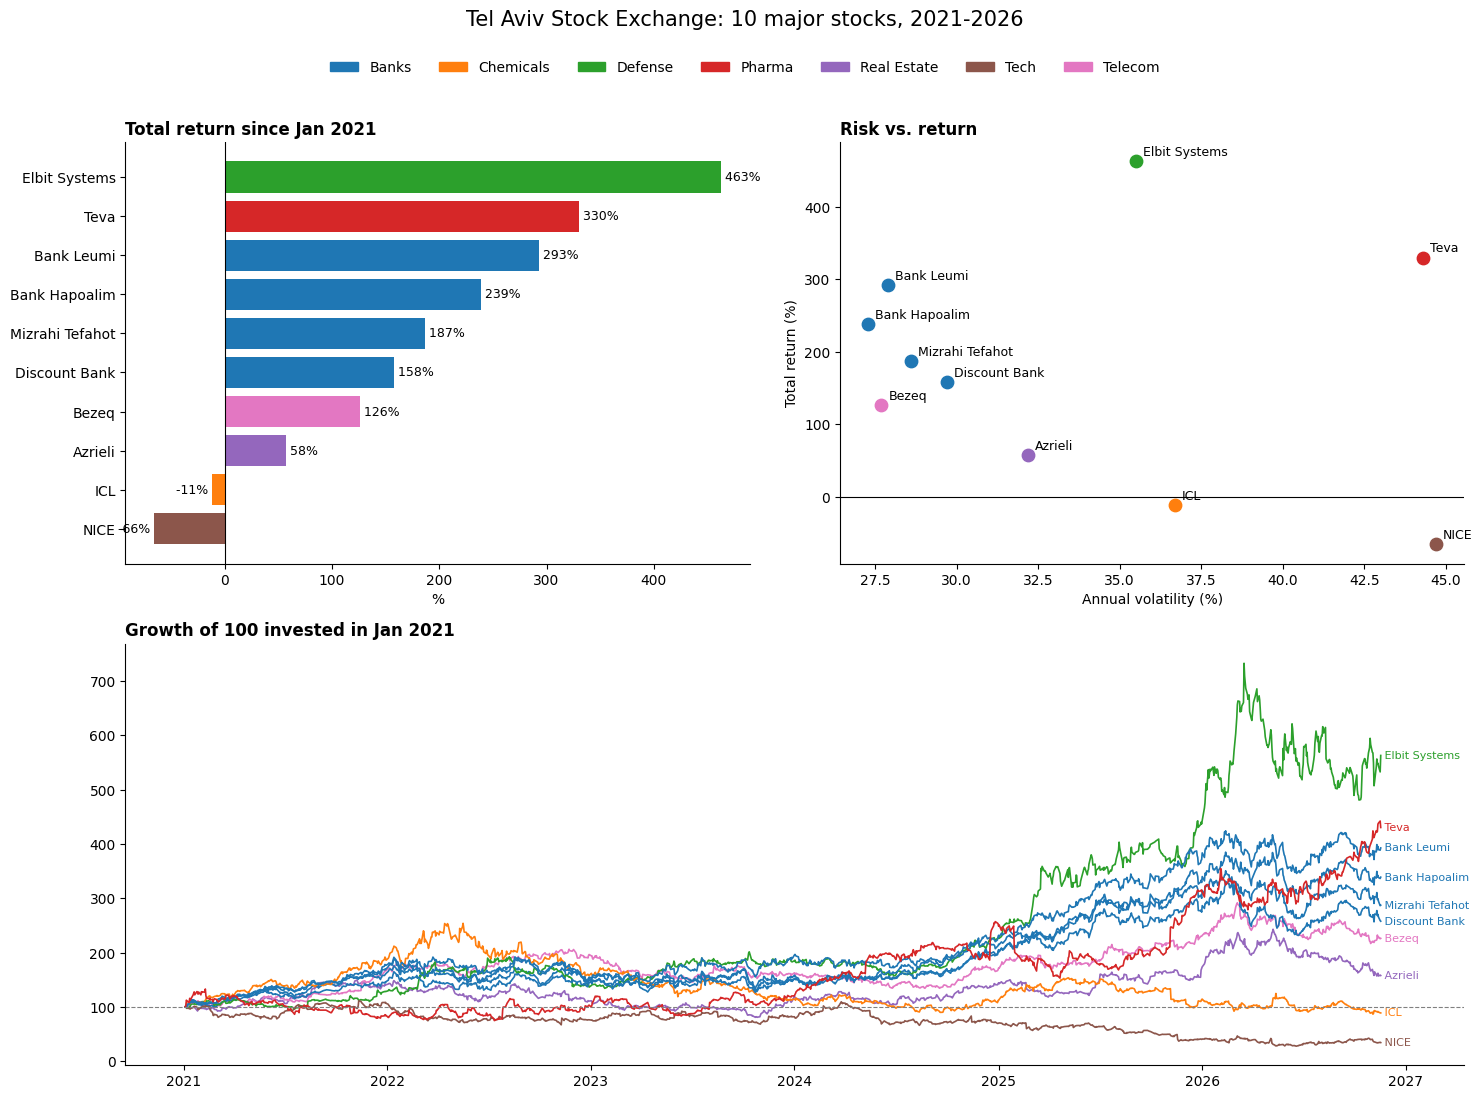

In [4]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

ret = sql("""
WITH first_last AS (
    SELECT ticker, MIN(Date) AS d0, MAX(Date) AS d1
    FROM prices GROUP BY ticker
)
SELECT s.name, s.sector,
       100.0 * (p1.close / p0.close - 1) AS total_return
FROM first_last f
JOIN prices p0 ON p0.ticker = f.ticker AND p0.Date = f.d0
JOIN prices p1 ON p1.ticker = f.ticker AND p1.Date = f.d1
JOIN stocks s  ON s.ticker = f.ticker
""")
df = ret.merge(vol[['name', 'volatility_pct']], on='name')
df = df.sort_values('total_return')

sectors = sorted(df['sector'].unique())
pal = plt.cm.tab10.colors
color = {sec: pal[i] for i, sec in enumerate(sectors)}

fig = plt.figure(figsize=(15, 11))
ax1 = fig.add_subplot(2, 2, 1)
ax2 = fig.add_subplot(2, 2, 2)
ax3 = fig.add_subplot(2, 1, 2)

# 1. Total return per stock
cols = [color[s] for s in df['sector']]
ax1.barh(df['name'], df['total_return'], color=cols)
ax1.axvline(0, color='black', linewidth=0.8)
for y, v in enumerate(df['total_return']):
    side = 'left' if v >= 0 else 'right'
    ax1.text(v, y, f' {v:.0f}% ', va='center', ha=side, fontsize=9)
ax1.set_title('Total return since Jan 2021',
              loc='left', fontweight='bold')
ax1.set_xlabel('%')

# 2. Risk vs. return
for _, r in df.iterrows():
    x, y = r['volatility_pct'], r['total_return']
    ax2.scatter(x, y, s=80, color=color[r['sector']])
    ax2.annotate(r['name'], (x, y), xytext=(5, 4),
                 textcoords='offset points', fontsize=9)
ax2.axhline(0, color='black', linewidth=0.8)
ax2.set_title('Risk vs. return', loc='left', fontweight='bold')
ax2.set_xlabel('Annual volatility (%)')
ax2.set_ylabel('Total return (%)')

# 3. Growth of 100 invested
growth = prices.apply(lambda c: c / c.dropna().iloc[0] * 100)
for t in growth.columns:
    name, sec = stocks[t]
    line = growth[t].dropna()
    ax3.plot(line.index, line, color=color[sec], linewidth=1.2)
    ax3.text(line.index[-1], line.iloc[-1], ' ' + name,
             fontsize=8, va='center', color=color[sec])
ax3.axhline(100, color='gray', linestyle='--', linewidth=0.8)
end = growth.index[-1] + pd.Timedelta(days=150)
ax3.set_xlim(right=end)
ax3.set_title('Growth of 100 invested in Jan 2021',
              loc='left', fontweight='bold')

for ax in (ax1, ax2, ax3):
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)

handles = [Patch(color=color[s], label=s) for s in sectors]
fig.legend(handles=handles, loc='upper center',
           ncol=len(sectors), frameon=False,
           bbox_to_anchor=(0.5, 0.96))
fig.suptitle('Tel Aviv Stock Exchange: 10 major stocks, 2021-2026',
             fontsize=15, y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig('tase_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()

## Key Findings

1. **Defense and pharma led.** Elbit Systems returned 464% and Teva 329% since January 2021.
2. **Banks delivered the best risk-adjusted performance.** All four major banks returned 161%–297% with the lowest volatility in the group (27%–30%).
3. **High risk did not guarantee high return.** Teva and NICE had almost identical volatility (~44%), yet Teva gained 329% while NICE lost 66%.
4. **Only two of ten stocks lost value:** NICE (-66%) and ICL (-11%).

*Returns are adjusted for dividends and splits. Data: Yahoo Finance via yfinance. Possible causes (e.g., defense demand, interest-rate environment) are hypotheses, not tested here.*